In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [9]:
from google.colab import files
uploaded = files.upload()

Saving Training Dataset.arff to Training Dataset (2).arff


In [10]:
from scipy.io import arff
import pandas as pd

# Chargement du fichier ARFF
data = arff.loadarff("Training Dataset (2).arff")
df = pd.DataFrame(data[0])  # Conversion en DataFrame

# 2. Conversion des colonnes catégorielles (bytes -> str)
for col in df.columns:
    if df[col].dtype == object:  # Si la colonne est de type object (bytes)
        df[col] = df[col].str.decode('utf-8')  # Conversion bytes -> str

# 3. Vérification
print("Types des colonnes:")
print(df.dtypes)


Types des colonnes:
having_IP_Address              object
URL_Length                     object
Shortining_Service             object
having_At_Symbol               object
double_slash_redirecting       object
Prefix_Suffix                  object
having_Sub_Domain              object
SSLfinal_State                 object
Domain_registeration_length    object
Favicon                        object
port                           object
HTTPS_token                    object
Request_URL                    object
URL_of_Anchor                  object
Links_in_tags                  object
SFH                            object
Submitting_to_email            object
Abnormal_URL                   object
Redirect                       object
on_mouseover                   object
RightClick                     object
popUpWidnow                    object
Iframe                         object
age_of_domain                  object
DNSRecord                      object
web_traffic                   

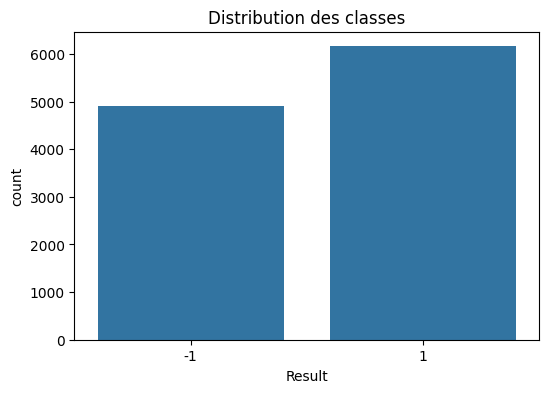

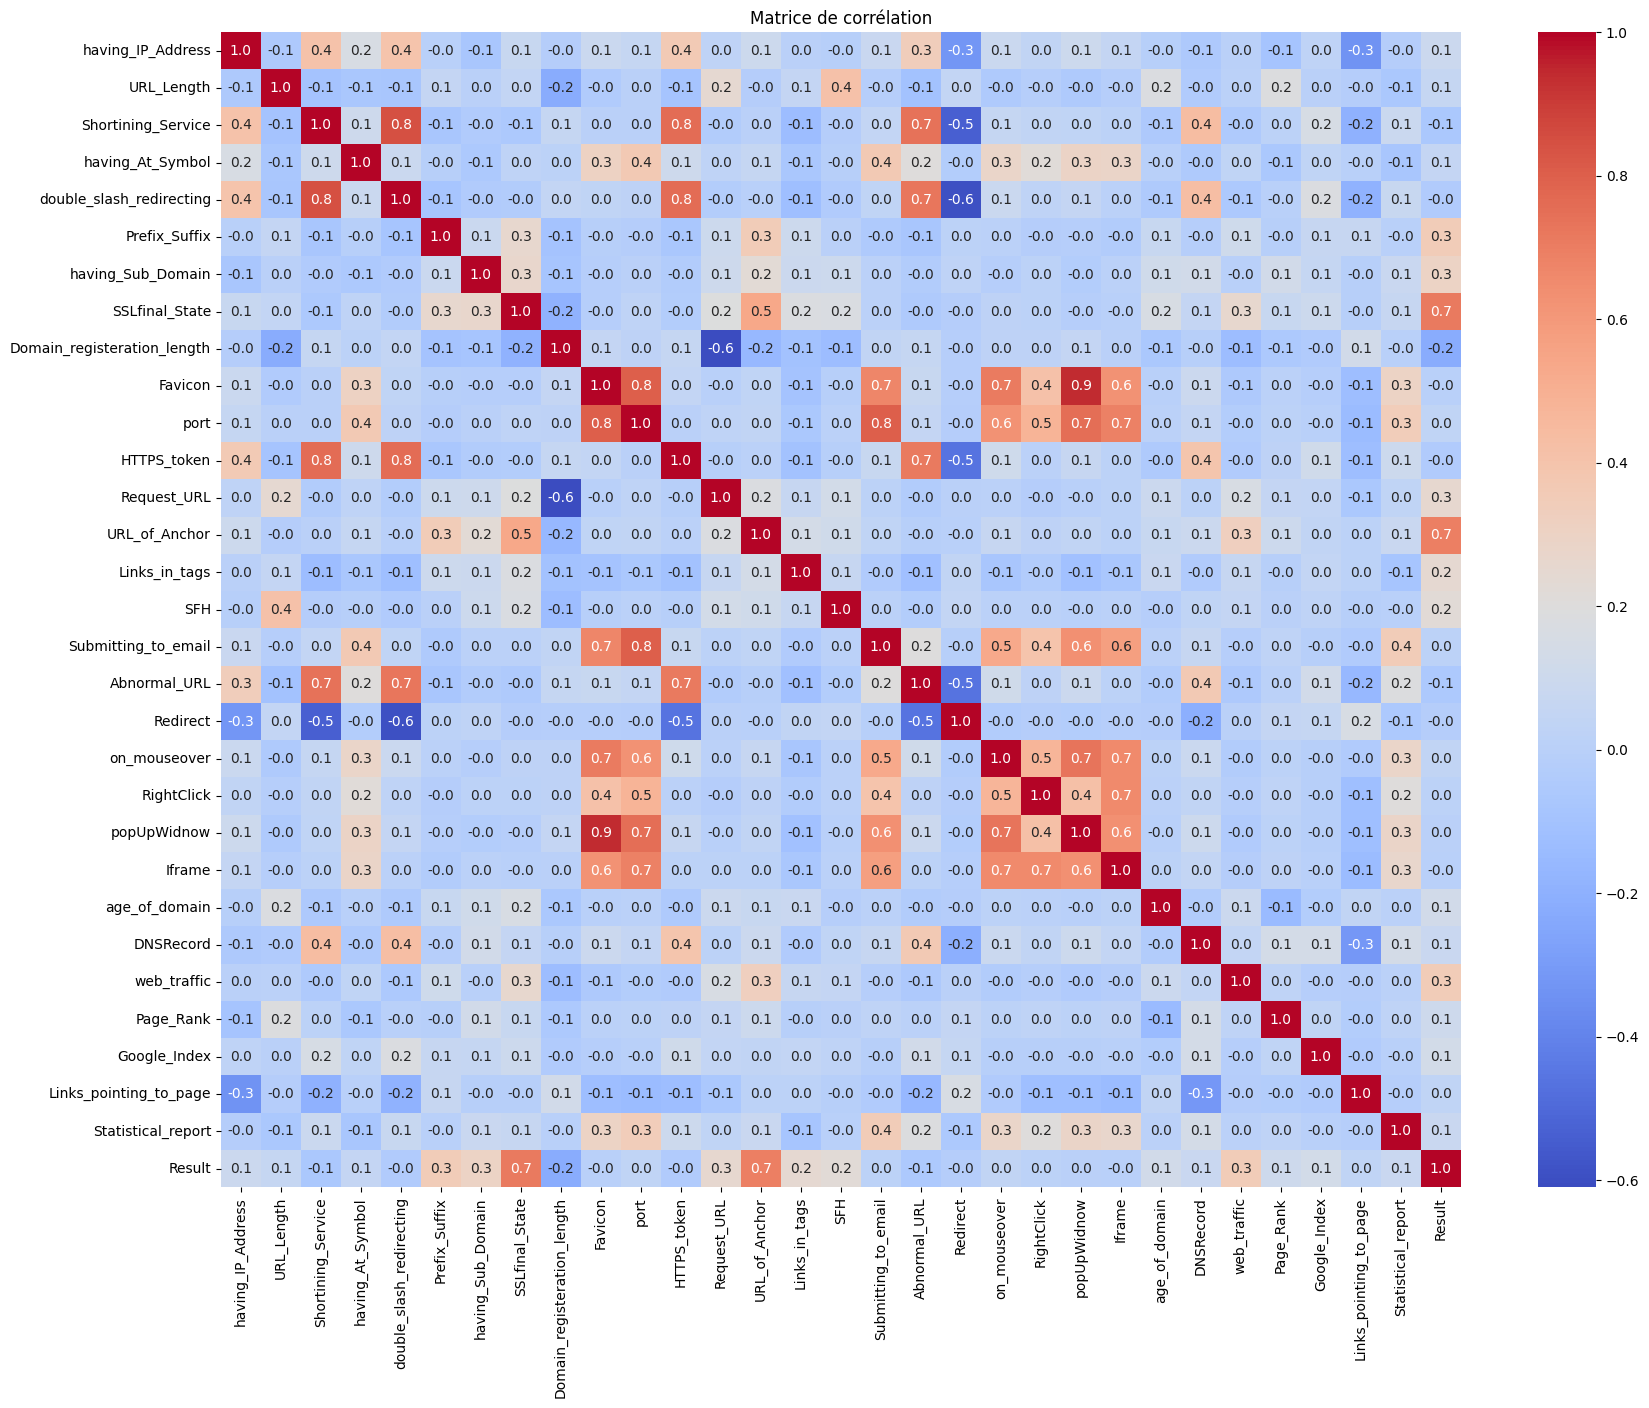

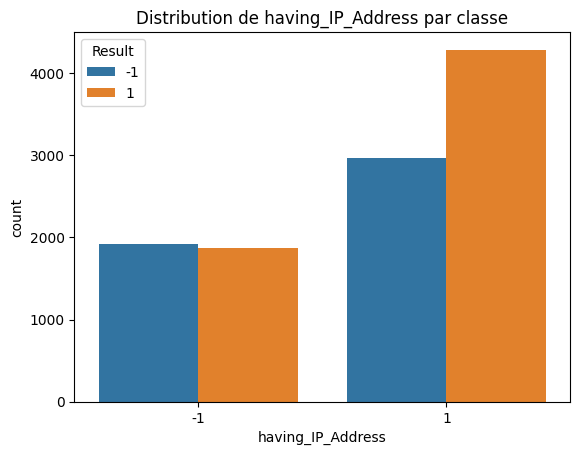

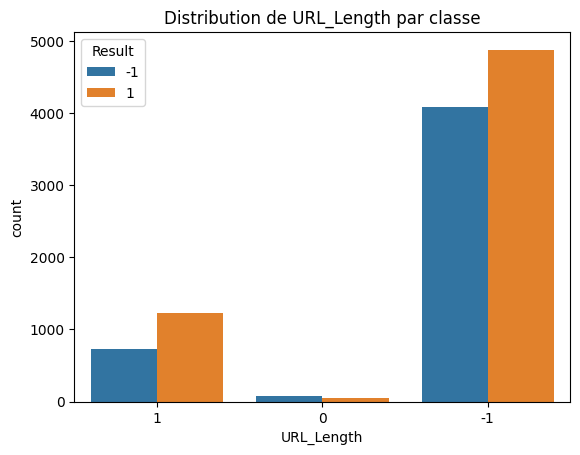

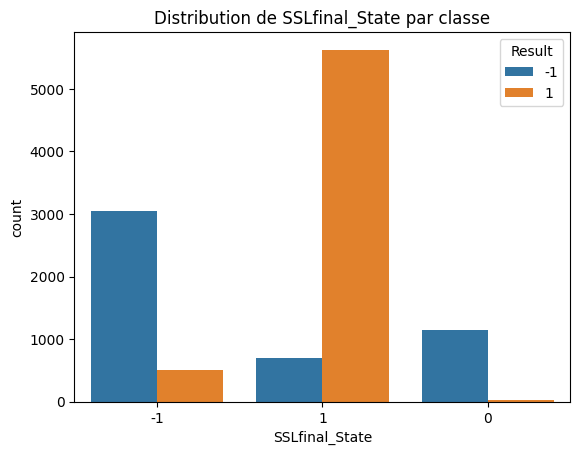

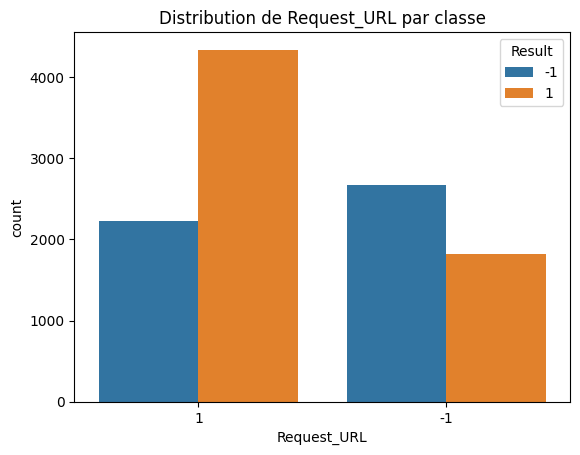

In [11]:
# Visualisation de la distribution de la cible
plt.figure(figsize=(6,4))
sns.countplot(x='Result', data=df)
plt.title('Distribution des classes')
plt.show()

# Matrice de corrélation
plt.figure(figsize=(20,15))
corr = df.corr()
sns.heatmap(corr, annot=True, fmt='.1f', cmap='coolwarm')
plt.title('Matrice de corrélation')
plt.show()

# Distribution de quelques caractéristiques importantes
features_to_plot = ['having_IP_Address', 'URL_Length', 'SSLfinal_State', 'Request_URL']
for feature in features_to_plot:
    plt.figure()
    sns.countplot(x=feature, hue='Result', data=df)
    plt.title(f'Distribution de {feature} par classe')
    plt.show()

In [12]:
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
def preprocess_data(df):
    # Suppression des doublons
    df = df.drop_duplicates()

    # Vérification des valeurs manquantes
    if df.isnull().sum().any():
        print("Valeurs manquantes détectées :")
        print(df.isnull().sum())
        df = df.fillna(df.mode().iloc[0])  # Imputation par le mode

    # Séparation features / target
    X = df.drop('Result', axis=1)
    y = df['Result']

    # Sélection des meilleures features (top 15)
    from sklearn.feature_selection import SelectKBest, f_classif

    selector = SelectKBest(f_classif, k=15)
    X_selected = selector.fit_transform(X, y)


    # Récupération des noms des colonnes sélectionnées
    selected_features = X.columns[selector.get_support()]
    print("\nFeatures sélectionnées :", list(selected_features))

    # Normalisation (StandardScaler pour les modèles sensibles à l'échelle)
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_selected)
    return X_scaled, y, selected_features

X, y, selected_features = preprocess_data(df)



Features sélectionnées : ['having_IP_Address', 'Shortining_Service', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Abnormal_URL', 'web_traffic', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report']


In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y  # Maintient la proportion des classes
)

print(f"\nTaille des données :")
print(f"- Train : {X_train.shape[0]} échantillons")
print(f"- Test  : {X_test.shape[0]} échantillons")


Taille des données :
- Train : 4679 échantillons
- Test  : 1170 échantillons


In [17]:
import numpy as np
from imblearn.over_sampling import SMOTE

if len(np.unique(y_train)) > 1 and abs(sum(y_train == 1) - sum(y_train == -1)) > 0.3 * len(y_train):
    print("\nApplication de SMOTE pour équilibrer les classes...")
    smote = SMOTE(random_state=42)
    X_train, y_train = smote.fit_resample(X_train, y_train)
    print("Nouvelle distribution :", pd.Series(y_train).value_counts())


🔧 Entraînement du modèle RandomForest...


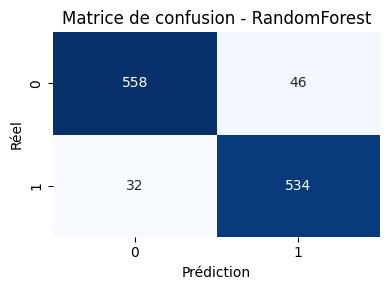


🔧 Entraînement du modèle XGBoost...


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [12:26:44] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


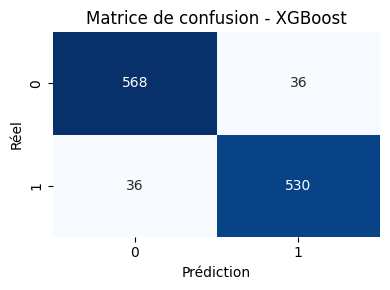

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(



🔧 Entraînement du modèle LightGBM...
[LightGBM] [Info] Number of positive: 2264, number of negative: 2415
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001148 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 52
[LightGBM] [Info] Number of data points in the train set: 4679, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.483864 -> initscore=-0.064566
[LightGBM] [Info] Start training from score -0.064566


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


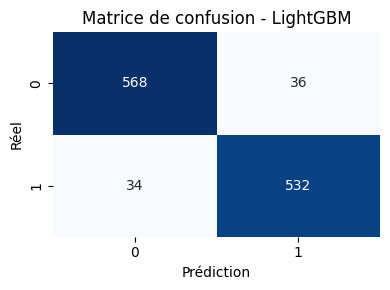


📊 Résumé des performances des modèles :
      Modèle  Accuracy  Précision  Rappel  F1-Score
RandomForest    0.9333     0.9336  0.9333    0.9333
     XGBoost    0.9385     0.9385  0.9385    0.9385
    LightGBM    0.9402     0.9402  0.9402    0.9402


In [18]:
# Sauvegarde des données prétraitées (optionnel)
preprocessed_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "selected_features": selected_features
}
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 📌 Assurer les bons labels pour XGBoost (0 et 1)
y_train = y_train.replace(-1, 0).astype(int)
y_test = y_test.replace(-1, 0).astype(int)


# 📊 Modèles à tester
models = {
    "RandomForest": RandomForestClassifier(random_state=42),
    "XGBoost": XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42),
    "LightGBM": LGBMClassifier(random_state=42)
}

# 📈 Stocker les scores ici
results = []

# 📦 Boucle sur les modèles
# 📈 Boucle sur les modèles
for name, model in models.items():
    print(f"\n🔧 Entraînement du modèle {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # ✅ Calcul des métriques (ajusté pour multiclasses)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    # 📊 Stockage dans le tableau de résultats
    results.append({
        "Modèle": name,
        "Accuracy": round(acc, 4),
        "Précision": round(prec, 4),
        "Rappel": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

    # 📉 Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"Matrice de confusion - {name}")
    plt.xlabel("Prédiction")
    plt.ylabel("Réel")
    plt.tight_layout()
    plt.show()

# 📋 Tableau récapitulatif
df_results = pd.DataFrame(results)
print("\n📊 Résumé des performances des modèles :")
print(df_results.to_string(index=False))



🔧 Entraînement du modèle RandomForest...


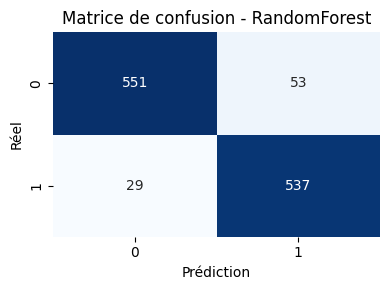


🔧 Entraînement du modèle XGBoost...


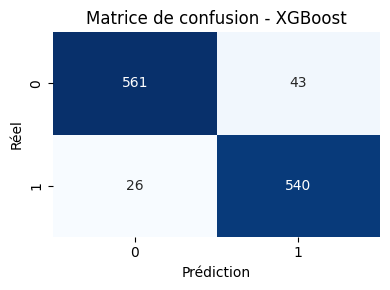


🔧 Entraînement du modèle LightGBM...
[LightGBM] [Info] Number of positive: 2264, number of negative: 2415
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000479 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 52
[LightGBM] [Info] Number of data points in the train set: 4679, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.483864 -> initscore=-0.064566
[LightGBM] [Info] Start training from score -0.064566


/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


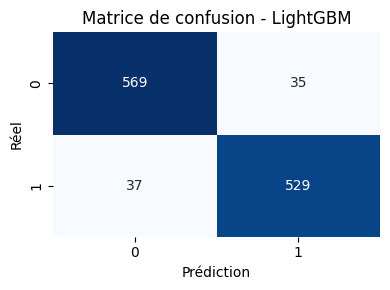


📊 Résumé des performances des modèles :
      Modèle  Accuracy  Précision  Rappel  F1-Score
RandomForest    0.9299     0.9307  0.9299    0.9299
     XGBoost    0.9410     0.9415  0.9410    0.9410
    LightGBM    0.9385     0.9385  0.9385    0.9385


In [19]:
# Sauvegarde des données prétraitées (optionnel)
preprocessed_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "selected_features": selected_features
}
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 📌 Assurer les bons labels pour XGBoost (0 et 1)
y_train = y_train.replace(-1, 0).astype(int)
y_test = y_test.replace(-1, 0).astype(int)


# 📊 Modèles à tester
models = {
    "RandomForest": RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, learning_rate=0.05, max_depth=5, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=100, learning_rate=0.05, num_leaves=31, random_state=42)
}

# 📈 Stocker les scores ici
results = []

# 📦 Boucle sur les modèles
# 📈 Boucle sur les modèles
for name, model in models.items():
    print(f"\n🔧 Entraînement du modèle {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    # ✅ Calcul des métriques (ajusté pour multiclasses)
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    # 📊 Stockage dans le tableau de résultats
    results.append({
        "Modèle": name,
        "Accuracy": round(acc, 4),
        "Précision": round(prec, 4),
        "Rappel": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

    # 📉 Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"Matrice de confusion - {name}")
    plt.xlabel("Prédiction")
    plt.ylabel("Réel")
    plt.tight_layout()
    plt.show()

# 📋 Tableau récapitulatif
df_results = pd.DataFrame(results)
print("\n📊 Résumé des performances des modèles :")
print(df_results.to_string(index=False))



🔧 Tuning et entraînement du modèle RandomForest...
Fitting 5 folds for each of 81 candidates, totalling 405 fits
Meilleurs hyperparamètres pour RandomForest: {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}


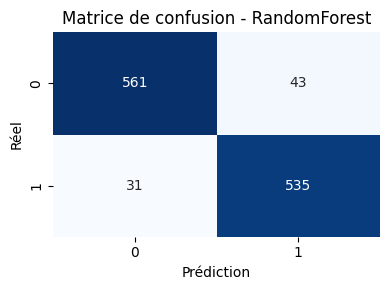


🔧 Tuning et entraînement du modèle XGBoost...
Fitting 5 folds for each of 36 candidates, totalling 180 fits
Meilleurs hyperparamètres pour XGBoost: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}


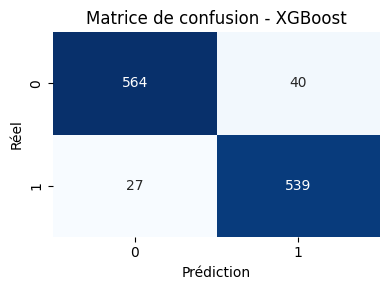


🔧 Tuning et entraînement du modèle LightGBM...
Fitting 5 folds for each of 54 candidates, totalling 270 fits
[LightGBM] [Info] Number of positive: 2264, number of negative: 2415
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000585 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 52
[LightGBM] [Info] Number of data points in the train set: 4679, number of used features: 15
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.483864 -> initscore=-0.064566
[LightGBM] [Info] Start training from score -0.064566
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further split

/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


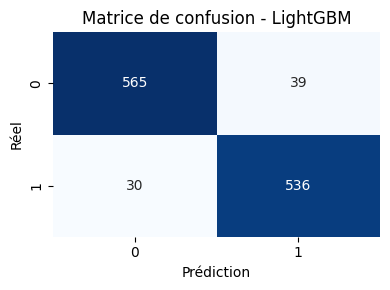


📊 Résumé des performances des modèles après tuning :
      Modèle                                                                           Best Params  Accuracy  Précision  Rappel  F1-Score
RandomForest {'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 200}    0.9368     0.9370  0.9368    0.9368
     XGBoost         {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'subsample': 1.0}    0.9427     0.9430  0.9427    0.9427
    LightGBM         {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100, 'num_leaves': 31}    0.9410     0.9412  0.9410    0.9410


In [20]:
from sklearn.model_selection import GridSearchCV
# Sauvegarde des données prétraitées (optionnel)
preprocessed_data = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "selected_features": selected_features
}
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# 📌 Assurer les bons labels pour XGBoost (0 et 1)
y_train = y_train.replace(-1, 0).astype(int)
y_test = y_test.replace(-1, 0).astype(int)
# Grilles d'hyperparamètres pour chaque modèle
param_grid = {
    "RandomForest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [5, 10, 15],
        "min_samples_split": [2, 5, 10],
        "min_samples_leaf": [1, 2, 4]
    },
    "XGBoost": {
        "n_estimators": [50, 100],
        "learning_rate": [0.01, 0.05, 0.1],
        "max_depth": [3, 5, 7],
        "subsample": [0.8, 1.0]
    },
    "LightGBM": {
        "n_estimators": [50, 100],
        "learning_rate": [0.01, 0.05, 0.1],
        "num_leaves": [31, 50, 100],
        "max_depth": [-1, 5, 10]
    }
}

# 📈 Stocker les résultats
results = []

# 📦 Boucle sur les modèles
for name, model in models.items():
    print(f"\n🔧 Tuning et entraînement du modèle {name}...")

    # GridSearchCV pour trouver les meilleurs hyperparamètres
    grid_search = GridSearchCV(estimator=model, param_grid=param_grid[name],
                               cv=5, n_jobs=-1, verbose=1, scoring='accuracy')

    # Entraîner avec GridSearchCV
    grid_search.fit(X_train, y_train)

    # Meilleur modèle et meilleurs paramètres
    best_model = grid_search.best_estimator_
    best_params = grid_search.best_params_
    print(f"Meilleurs hyperparamètres pour {name}: {best_params}")

    # Prédictions avec le meilleur modèle
    y_pred = best_model.predict(X_test)

    # Calcul des métriques
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    # Stocker dans le tableau des résultats
    results.append({
        "Modèle": name,
        "Best Params": str(best_params),
        "Accuracy": round(acc, 4),
        "Précision": round(prec, 4),
        "Rappel": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

    # Matrice de confusion
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f"Matrice de confusion - {name}")
    plt.xlabel("Prédiction")
    plt.ylabel("Réel")
    plt.tight_layout()
    plt.show()

# Résumé des performances des modèles
df_results = pd.DataFrame(results)
print("\n📊 Résumé des performances des modèles après tuning :")
print(df_results.to_string(index=False))
